# ¿Quién da más de qué hablar en la UNISON?

Hay una pregunta que parece sencilla y que, al contestarla, revela mucho sobre la forma en que la Universidad de Sonora aparece en el archivo de noticias: ¿quién da más de qué hablar?

No se trata de una curiosidad. Detrás de cada nota hay una facultad, un programa, una comunidad y una manera de contar la institución. Al medir la frecuencia con que cada programa aparece en las noticias se puede observar qué áreas concentran la conversación pública y cuáles quedan en un segundo plano.

Este cuaderno cuenta esa historia desde el inicio: cómo se construyó el archivo, qué contiene, cómo se convirtió el texto en datos, qué se encontró y qué significa.


## 1. La pregunta que mueve la historia

La historia comienza con una decisión metodológica: en lugar de leer noticias aisladas, se decidió escuchar el archivo completo. La pregunta se formuló así: si se pudiera ordenar a todos los programas académicos por la frecuencia con que son mencionados en las noticias, ¿qué forma tendría ese orden y cómo cambiaría con el tiempo?

Responderla exige un archivo amplio, una forma confiable de identificar programas dentro del texto y una manera de distinguir la presencia real de cada programa de la simple casualidad de que una nota mencione varios. Por eso el trabajo se organizó en etapas: extracción, limpieza, identificación de menciones, medición, análisis temático y narración.


## 2. Cómo se construyó el archivo

El punto de partida fue el portal de Noticias Anteriores de la UNISON. El sitio no ofrece una descarga directa: la información se consulta con un formulario que filtra por año y por mes. El formulario tenía una limitación importante: cuando se consultaba un mes concreto, el portal devolvía como máximo 200 resultados. Para evitar perder notas, se consultó cada año completo usando la opción de mes vacío, que devuelve el año sin ese tope.

La descarga se hizo año por año, de 2003 a 2026, con una pausa entre consultas para no saturar el servidor. De cada resultado se extrajo el título, la fecha original, la fecha en formato ISO, el enlace y el año. Después se eliminaron los enlaces repetidos, conservando la versión con título informativo cuando existía. El archivo crudo quedó con 37,975 registros.

No todo lo que aparece en ese archivo es una nota periodística interna. Al filtrar por el patrón de notas del portal se descartaron 93 enlaces que correspondían a archivos, portales externos o páginas que no eran noticias. El corpus analizable quedó con 37,882 notas internas, publicadas entre 2003 y octubre de 2026. El archivo cubre 286 meses; los únicos meses ausentes son noviembre y diciembre de 2026, porque el corte del corpus es anterior.

Cada una de esas 37,882 notas tiene título, fecha, enlace, año y cuerpo. Doce notas conservaron título vacío o con un punto, pero se mantuvieron porque su cuerpo sí aportaba texto. La descarga de cuerpos se hizo nota por nota, extrayendo el contenido del bloque `div.entry-content`, eliminando scripts, estilos, navegación, formularios y otros elementos que no forman parte del texto periodístico. Se obtuvieron 37,882 cuerpos válidos, es decir, el 100% de cobertura, con alrededor de 95.35 millones de caracteres.


## 3. Cómo se convirtió el texto en datos

El paso siguiente fue identificar programas académicos dentro del texto. Se construyó un catálogo canónico de 131 programas: 47 licenciaturas, 14 ingenierías, 11 especialidades y 59 familias de posgrado. En el posgrado se tomó una decisión importante: la maestría y el doctorado de un mismo campo se agruparon en una sola entrada `Posgrado en X`, aunque el nombre no fuera idéntico. Así se evita fragmentar la presencia de un área entre niveles que, en la práctica, comparten tema y comunidad.

La búsqueda se hizo sobre el título y el cuerpo de cada nota. Una nota puede mencionar varios programas y el mismo programa cuenta una sola vez por nota. También se resolvieron listas coordinadas: cuando el texto decía “Psicología y Comunicación”, se separaron ambos programas; cuando el nombre oficial contenía una “y” que no era una lista, se conservó completo. El resultado fueron 22,403 menciones en 15,386 notas, es decir, el 40.62% del corpus menciona al menos un programa del catálogo.

Con esas menciones se calcularon la cobertura institucional, la participación de cada programa, la brecha entre pregrado y posgrado, el olvido mediático, la concentración y la evolución temporal. Después se modelaron los temas y se construyó una segunda lectura temática para clasificar las notas en áreas.


## 4. La presencia por año

Una de las preguntas centrales para la entrega fue cómo evoluciona la presencia del posgrado año con año, desde 2003 hasta 2026. Para responderla no basta con contar notas: un año con más actividad institucional produce más notas y podría parecer un año con más presencia. Por eso la medición se normalizó: se calculan menciones por cada 1,000 notas publicadas en el periodo.

La gráfica siguiente muestra esa evolución separada por nivel. En ella se observa que el pregrado siempre tuvo una presencia mayor, pero que el posgrado también ganó terreno relativo con el paso de los años.


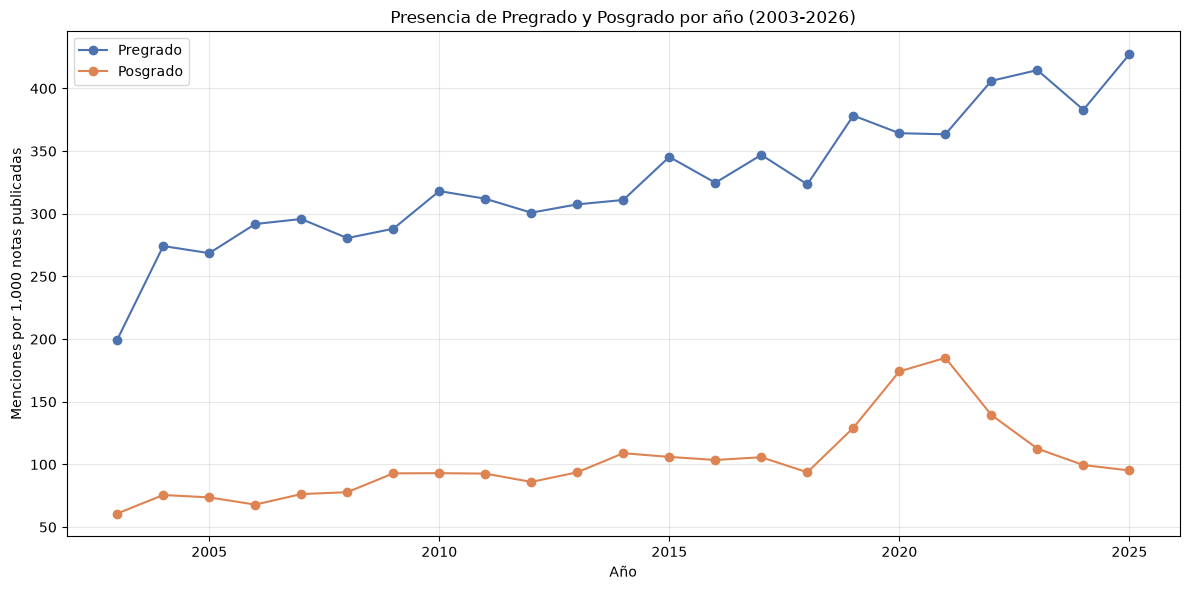

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

PROCESADO = Path('../data/processed').resolve()

evolucion = pd.read_parquet(PROCESADO / 'evolucion_nivel.parquet')
periodos = evolucion[(evolucion['Periodo_Tipo'] == 'Año') & (~evolucion['Es_Periodo_Parcial'])]
pivote = periodos.pivot(index='Periodo', columns='Grupo', values='Notas por 1000').fillna(0).sort_index()

fig, ax = plt.subplots(figsize=(12, 6))
for i, grupo in enumerate(['Pregrado', 'Posgrado']):
    color = ['#4c72b0', '#dd8452'][i]
    ax.plot(pivote.index.astype(int), pivote[grupo], marker='o', label=grupo, color=color)
ax.set_xlabel('Año')
ax.set_ylabel('Menciones por 1,000 notas publicadas')
ax.set_title('Presencia de Pregrado y Posgrado por año (2003-2026)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


La lectura de la gráfica no es una línea recta. En los primeros años, la presencia del pregrado ronda las 280 menciones por cada 1,000 notas; en la década de 2010 sube a alrededor de 327; y en la década de 2020 llega a casi 398. El posgrado sigue un camino parecido, pero desde una base mucho menor: alrededor de 77 en los 2000, 102 en los 2010 y 129 en los 2020. La diferencia no desaparece; incluso se amplía en términos absolutos. El pico del pregrado está en 2025, con 427 menciones por cada 1,000 notas, mientras que el pico del posgrado está en 2021, con 185.

Esa evolución cuenta una parte de la historia: la agenda crece y cambia, pero la estructura de fondo se mantiene. El posgrado no deja de ser minoritario, aunque su presencia relativa mejora con los años.


## 5. El protagonista de cada año

La evolución por nivel dice qué pasó con el conjunto, pero no quién ocupó el centro de la conversación en cada año. Para responder a esa pregunta se calculó, año por año, cuál fue el programa con más menciones. El resultado permite ver que la agenda no siempre estuvo dominada por el mismo programa y que hubo momentos de cambio.


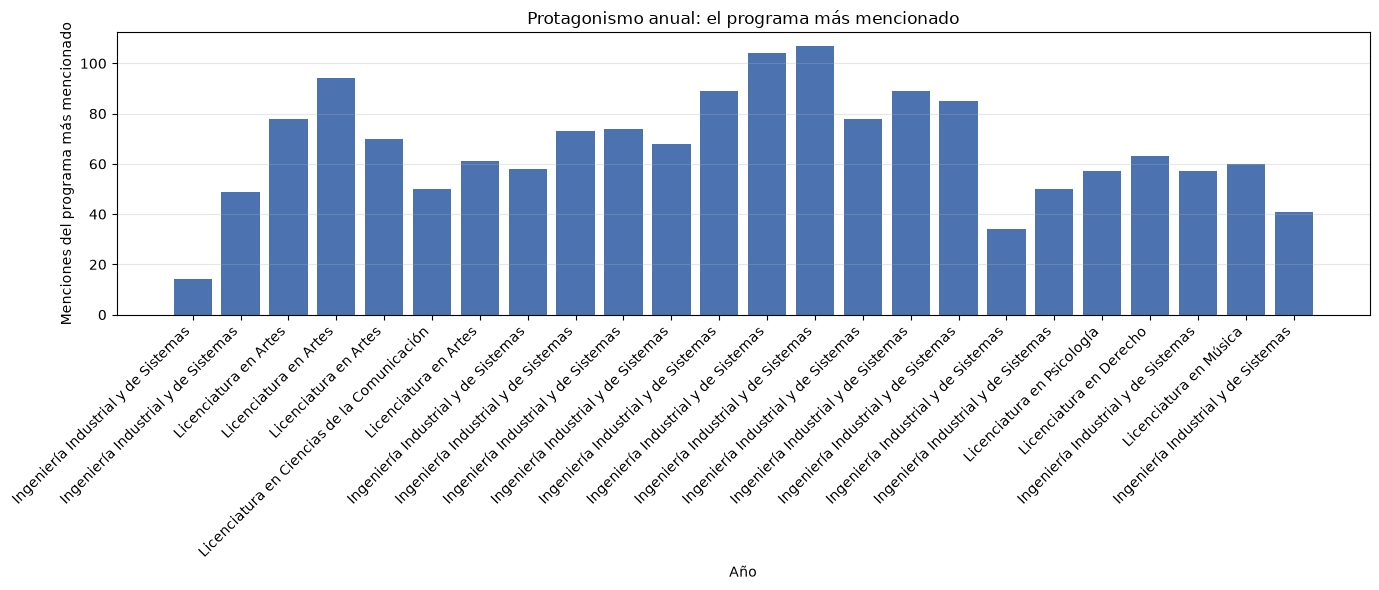

In [2]:
menciones = pd.read_parquet('../data/interim/noticias_limpias_full.parquet')
menciones['Año'] = pd.to_numeric(menciones['Año'], errors='coerce')
top_anual = (
    menciones.dropna(subset=['Año'])
    .groupby('Año')['Programa'].value_counts().reset_index(name='Menciones')
    .sort_values(['Año', 'Menciones'], ascending=[True, False])
)
top_anual = top_anual.groupby('Año').head(1).sort_values('Año')

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(top_anual['Año'], top_anual['Menciones'], color='#4c72b0')
ax.set_xlabel('Año')
ax.set_ylabel('Menciones del programa más mencionado')
ax.set_title('Protagonismo anual: el programa más mencionado')
ax.grid(axis='y', alpha=0.3)
ax.set_xticks(top_anual['Año'], top_anual['Programa'], rotation=45, ha='right')
plt.tight_layout()
plt.show()


La gráfica muestra que el protagonismo anual tiene nombres concretos. En los primeros años aparecen Ingeniería Industrial y de Sistemas y Licenciatura en Artes; más tarde, entre 2005 y 2009, las artes y la comunicación ocupan el centro. A partir de 2010, Ingeniería Industrial y de Sistemas se convierte en el programa más mencionado en casi todos los años, con excepciones como 2022, cuando aparece Licenciatura en Psicología; 2023, con Licenciatura en Derecho; y 2025, con Licenciatura en Música.

Esa alternancia es parte de la historia: no hay un único protagonista permanente, sino una competencia entre áreas que cambia con los ciclos institucionales, los eventos y las coyunturas.


## 6. Los programas que casi no aparecen

La historia no se entiende solo con los programas que dominan. También importa el silencio. Para medirlo se identificó el cuartil inferior de cobertura, es decir, los programas con menos notas en todo el archivo. El resultado es contundente: hay dos programas sin ninguna mención y varios con una o dos apariciones en más de dos décadas de noticias.

La tabla siguiente muestra el conjunto completo de programas con cobertura muy baja, su nivel y la categoría de olvido que les corresponde. En la lectura se observa que casi todos pertenecen al posgrado; el pregrado aparece solo en casos aislados.


In [3]:
olvido = pd.read_parquet(PROCESADO / 'olvido_mediatico.parquet')
display(
    olvido[['Programa', 'Grupo', 'Notas', 'Categoria_Olvido']]
    .sort_values(['Notas', 'Programa'])
    .reset_index(drop=True)
)


,Programa,Grupo,Notas,Categoria_Olvido
0,Especialidad en Enfermería Pediátrica,Posgrado,0,Sin mención
1,Especialidad en Enfermería Quirúrgica Perioper...,Posgrado,0,Sin mención
2,Posgrado en Ciencias Naturales,Posgrado,1,Mención única
3,Posgrado en Endocrinología Ginecológica,Posgrado,1,Mención única
4,Posgrado en Bionanotecnología,Posgrado,2,Cobertura muy baja
5,Posgrado en Docencia en Enseñanza Media Superior,Posgrado,2,Cobertura muy baja
6,Posgrado en Ingeniería Mecatrónica,Posgrado,2,Cobertura muy baja
7,Posgrado en Investigación Educativa,Posgrado,2,Cobertura muy baja
8,Especialidad en Derecho Penal y Criminalística,Posgrado,3,Cobertura muy baja
9,Posgrado en Enfermería de Práctica Avanzada,Posgrado,4,Cobertura muy baja


La tabla confirma una asimetría profunda: **31 de los 34 programas del cuartil inferior son de posgrado**, y los tres casos de pregrado son excepciones. Las dos especialidades sin mención son Enfermería Pediátrica y Enfermería Quirúrgica Perioperatoria. Después aparecen programas con una sola mención, como Ciencias Naturales y Endocrinología Ginecológica, y un bloque amplio de posgrados con dos a diecisiete notas.

Esa ausencia no es un detalle menor: significa que una parte importante de la oferta de posgrado no tiene presencia sostenida en el relato público de la universidad. La historia de la UNISON no solo está marcada por quién habla, sino por quién casi no aparece.


## 7. Cómo se miran los temas

Además de contar menciones, la historia se pregunta de qué se habla. Para eso se usaron dos estrategias complementarias. La primera representa cada nota como un conjunto de palabras ponderadas: no todas las palabras pesan igual, porque algunas son muy frecuentes y aportan poco, mientras que otras son más específicas y ayudan a distinguir un texto de otro. Esa representación se conoce como **TF-IDF**, y su función es convertir el lenguaje en números que reflejen importancia relativa.

La segunda estrategia toma esa representación y busca estructuras: agrupa las notas en una cantidad fija de temas, de modo que cada nota queda explicada por una combinación de ellos. El método usado fue **NMF**, una descomposición que trabaja con valores no negativos y que suele producir temas interpretables. Con 15 temas, el modelo permitió observar qué tipo de conversación rodea a cada programa y comparar el perfil temático del pregrado con el del posgrado.

Para que los métodos no queden como nombres abstractos, los siguientes ejemplos muestran cómo se calculan con textos pequeños.


**Ejemplo de TF-IDF.** Se toman tres notas breves y se calcula el peso de cada palabra. Las palabras que aparecen en todas las notas pierden peso; las que distinguen a una nota ganan importancia.


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

corpus_ejemplo = [
    'La universidad inauguró un concierto de música en el teatro',
    'El hospital atendió a pacientes con medicina preventiva',
    'El equipo de fútbol ganó la medalla en el torneo',
]
etiquetas = ['Nota cultural', 'Nota de salud', 'Nota deportiva']
vectorizador = TfidfVectorizer()
matriz = vectorizador.fit_transform(corpus_ejemplo)
tabla_tfidf = pd.DataFrame(
    matriz.toarray().round(2),
    columns=vectorizador.get_feature_names_out(),
    index=etiquetas,
)
display(tabla_tfidf)


,atendió,con,concierto,de,el,en,equipo,fútbol,ganó,hospital,...,la,medalla,medicina,música,pacientes,preventiva,teatro,torneo,un,universidad
Nota cultural,0.0,0.0,0.35,0.27,0.21,0.27,0.00,0.00,0.00,0.0,...,0.27,0.00,0.0,0.35,0.0,0.0,0.35,0.00,0.35,0.35
Nota de salud,0.4,0.4,0.00,0.00,0.23,0.00,0.00,0.00,0.00,0.4,...,0.00,0.00,0.4,0.00,0.4,0.4,0.00,0.00,0.00,0.00
Nota deportiva,0.0,0.0,0.00,0.27,0.41,0.27,0.35,0.35,0.35,0.0,...,0.27,0.35,0.0,0.00,0.0,0.0,0.00,0.35,0.00,0.00


**Ejemplo de NMF.** La matriz anterior se descompone en dos temas. Cada nota queda con un peso en cada tema, y cada tema queda descrito por las palabras que más lo representan. Así se pasa de una tabla de palabras a una tabla de temas.


In [5]:
from sklearn.decomposition import NMF

modelo_ejemplo = NMF(n_components=2, init='random', random_state=20261103)
pesos_documento = modelo_ejemplo.fit_transform(matriz)
pesos_palabra = modelo_ejemplo.components_

display(
    pd.DataFrame(
        pesos_documento.round(2),
        columns=['Tema 1', 'Tema 2'],
        index=etiquetas,
    )
)
display(
    pd.DataFrame(
        pesos_palabra.round(2),
        columns=vectorizador.get_feature_names_out(),
        index=['Tema 1', 'Tema 2'],
    )
)


,Tema 1,Tema 2
Nota cultural,0.49,0.00
Nota de salud,0.00,0.61
Nota deportiva,0.49,0.02


,atendió,con,concierto,de,el,en,equipo,fútbol,ganó,hospital,...,la,medalla,medicina,música,pacientes,preventiva,teatro,torneo,un,universidad
Tema 1,0.00,0.00,0.36,0.54,0.62,0.54,0.35,0.35,0.35,0.00,...,0.54,0.35,0.00,0.36,0.00,0.00,0.36,0.35,0.36,0.36
Tema 2,0.65,0.65,0.00,0.00,0.39,0.00,0.01,0.01,0.01,0.65,...,0.00,0.01,0.65,0.00,0.65,0.65,0.00,0.01,0.00,0.00


**Ejemplo de similitud coseno.** La similitud coseno mide el ángulo entre dos vectores: si dos textos comparten palabras importantes, sus vectores apuntan en una dirección parecida y la similitud se acerca a 1. En la clasificación temática, cada nota se compara con las descripciones de las áreas y se queda con la de mayor similitud. El ejemplo siguiente compara una nota cultural con varias áreas.


In [6]:
import sys
from sklearn.metrics.pairwise import cosine_similarity

sys.path.insert(0, str(Path('..').resolve() / 'src' / 'features'))
from taxonomia_categorias import CATEGORIAS

nombres = list(CATEGORIAS)
vectorizador_categorias = TfidfVectorizer()
descripciones = vectorizador_categorias.fit_transform(list(CATEGORIAS.values()))
consulta = vectorizador_categorias.transform(
    ['La universidad inauguró un concierto de música en el teatro']
)
similitudes = cosine_similarity(consulta, descripciones).ravel()
tabla_similitud = (
    pd.DataFrame({'Categoría': nombres, 'Similitud': similitudes.round(3)})
    .sort_values('Similitud', ascending=False)
    .head(5)
)
display(tabla_similitud)


,Categoría,Similitud
4,Artes y cultura,0.390
17,Internacionalización y movilidad,0.146
0,Admisión e ingreso,0.000
2,Investigación y ciencia,0.000
1,Oferta educativa y docencia,0.000


La nota cultural se acerca más a **Artes y cultura**, que es justamente la categoría que el sistema le asignaría. Ese mismo procedimiento se aplicó a las 15,386 notas con programa. El resultado permite responder qué programa entra en qué categoría y de qué habla más. La tabla siguiente muestra la categoría principal de los programas con más menciones.


In [7]:
categorias_programas = pd.read_parquet(PROCESADO / 'categorias_programas.parquet')
principal = (
    categorias_programas[categorias_programas['Ranking'] == 1]
    .sort_values('Menciones', ascending=False)
    .head(15)
)
display(
    principal[['Programa', 'Grupo', 'Categoria', 'Peso_Porcentaje', 'Menciones']]
    .reset_index(drop=True)
)


,Programa,Grupo,Categoria,Peso_Porcentaje,Menciones
0,Licenciatura en Artes,Pregrado,Artes y cultura,72.53,499
1,Licenciatura en Música,Pregrado,Artes y cultura,66.01,470
2,Licenciatura en Artes Escénicas,Pregrado,Artes y cultura,61.09,325
3,Licenciatura en Medicina,Pregrado,Salud y medicina,48.29,296
4,Licenciatura en Derecho,Pregrado,Derecho y justicia,22.84,254
5,Posgrado en Derecho,Posgrado,Derecho y justicia,46.01,225
6,Licenciatura en Enfermería,Pregrado,Salud y medicina,46.62,221
7,Licenciatura en Ciencias de la Comunicación,Pregrado,Divulgación y medios,21.27,218
8,Licenciatura en Artes Plásticas,Pregrado,Artes y cultura,63.20,170
9,Ingeniería Industrial y de Sistemas,Pregrado,Sustentabilidad y medio ambiente,11.30,170


La lectura es nítida: **Artes, Música y Artes Escénicas** se concentran en **Artes y cultura**; **Medicina, Enfermería y Nutrición** en **Salud y medicina**; **Derecho y el Posgrado en Derecho** en **Derecho y justicia**; **Comunicación** en **Divulgación y medios**. Las ingenierías aparecen más repartidas, con peso en **Sustentabilidad y medio ambiente** y en **Otros**, lo que sugiere una cobertura menos especializada. El Posgrado en Ciencias y Tecnología de Alimentos se asocia a **Investigación y ciencia**, no a la categoría agropecuaria, lo que muestra que su relato público se construye más desde la ciencia que desde el campo.


## 8. Los tres actos

La historia se organiza en tres actos. El primero describe el estatus quo: quién concentra la conversación. El segundo muestra cómo cambia la agenda con los años. El tercero se detiene en el discurso: de qué se habla cuando se habla de cada programa.

### Acto I: el estatus quo

La historia comienza con una voz fuerte y concentrada. En el archivo, un puñado de programas acumula una parte desproporcionada de las menciones, mientras el resto aparece de manera más dispersa. Esa concentración no es un accidente de un año: se sostiene en el tiempo y define la primera respuesta a la pregunta inicial.

![Top 20 de programas por cobertura](../reports/figures/fig01_top20_cobertura.png)

La gráfica anterior ordena a los veinte programas más mencionados. En la cima aparecen Ingeniería Industrial y de Sistemas, Licenciatura en Derecho, Licenciatura en Ciencias de la Comunicación, Ingeniería Civil e Ingeniería Química; más abajo, pero todavía dentro del grupo visible, aparece el Posgrado en Ciencias y Tecnología de Alimentos. La lectura es clara: la conversación institucional tiene dueños reconocibles y una mayoría de programas que casi no aparece.

### Acto II: la evolución de los programas

El segundo acto no repite la evolución por nivel. Aquí la mirada se pone en los programas concretos: cómo se mueve cada uno a lo largo de los años. El mapa de calor siguiente muestra las notas por año de los doce programas más mencionados; las celdas más oscuras indican más presencia y las más claras, menos.


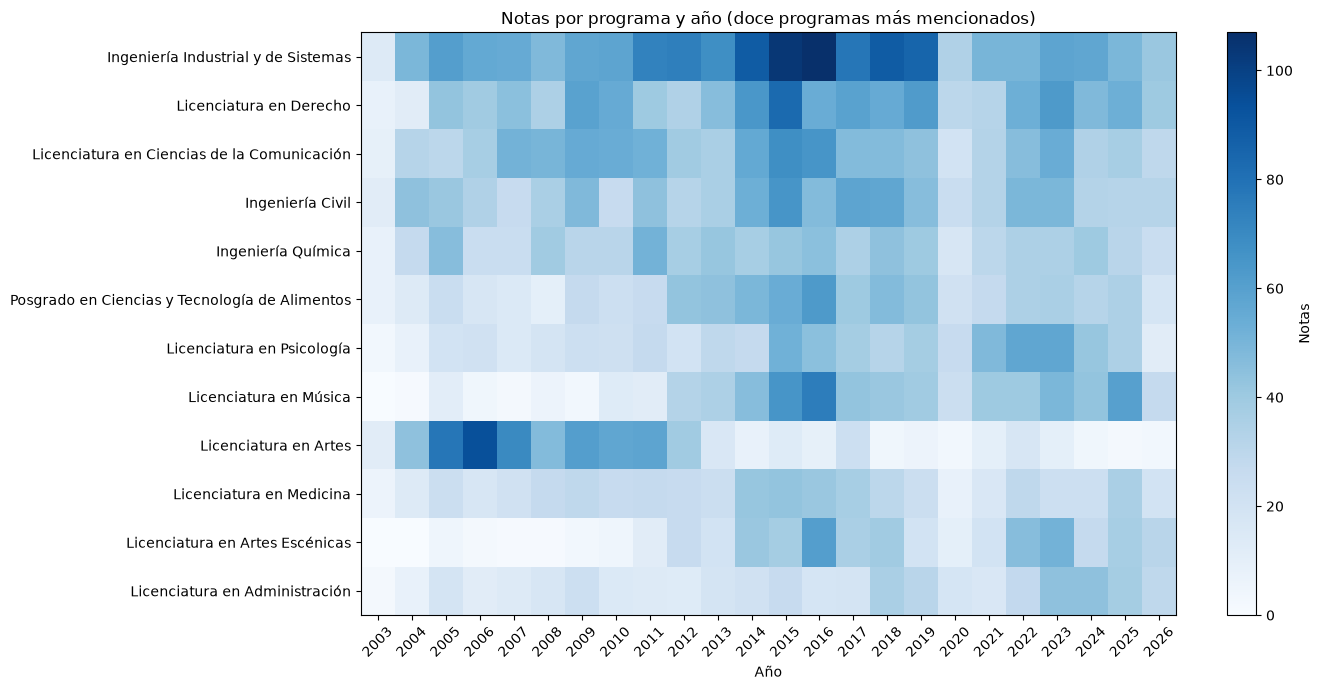

In [8]:
cobertura = pd.read_parquet(PROCESADO / 'cobertura_programas.parquet')
anual = pd.read_parquet(PROCESADO / 'cobertura_anual.parquet')
top_programas = cobertura.head(12)['Programa'].tolist()
sub = anual[anual['Programa'].isin(top_programas)]
pivote_anual = (
    sub.pivot(index='Programa', columns='Año', values='Notas')
    .reindex(top_programas)
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(14, 7))
imagen = ax.imshow(pivote_anual.values, aspect='auto', cmap='Blues')
ax.set_xticks(range(len(pivote_anual.columns)), [str(a) for a in pivote_anual.columns], rotation=45)
ax.set_yticks(range(len(pivote_anual.index)), pivote_anual.index)
ax.set_xlabel('Año')
ax.set_title('Notas por programa y año (doce programas más mencionados)')
fig.colorbar(imagen, ax=ax, label='Notas')
plt.tight_layout()
plt.show()


El mapa de calor permite ver trayectorias que la gráfica de niveles no muestra. Ingeniería Industrial y de Sistemas mantiene una franja oscura durante casi todo el periodo; Derecho y Comunicación ganan intensidad en los años intermedios; Música y Artes concentran su presencia en momentos específicos; el Posgrado en Ciencias y Tecnología de Alimentos tiene una columna visible en la década de 2010. La evolución no es un bloque uniforme: es un conjunto de trayectorias que se encienden y se apagan en momentos distintos.

### Acto III: el discurso

El tercer acto se detiene en el contenido. Cada programa no solo aparece más o menos: aparece dentro de un marco temático. Las artes se cuentan desde la cultura, la salud desde la medicina y la atención, las ingenierías desde la técnica y la industria, y el posgrado desde la investigación y la especialización. Esa es la parte más rica de la narrativa, porque muestra que la presencia no es solo cantidad: también es forma.

![Distribución de categorías](../reports/figures/fig07_categorias.png)

La gráfica anterior distribuye las notas entre las áreas temáticas. Artes y cultura ocupa el primer lugar, seguida por oferta educativa y docencia, eventos académicos, salud y medicina e investigación y ciencia. La categoría “Otros” reúne las notas que no alcanzaron similitud suficiente con ninguna área, lo que recuerda que una parte del archivo cuenta actividades cotidianas o textos breves que no encajan en un marco temático claro. La lectura de conjunto es que la UNISON se cuenta sobre todo a través de la cultura, la docencia, los eventos y la salud, y que el posgrado, cuando aparece, lo hace con un lenguaje más especializado.


## 9. Discusión

Los resultados permiten sostener tres ideas. La primera es que la cobertura mediática de la UNISON está concentrada: unos pocos programas ocupan una parte importante de la conversación y muchos otros aparecen de forma marginal. Esa concentración no es un fenómeno de un año ni de un programa aislado; es una estructura que se mantiene a lo largo del archivo. La segunda es que la brecha entre pregrado y posgrado no se corrige con el tiempo: aunque ambos niveles ganan presencia relativa, el pregrado conserva una ventaja amplia. La tercera es que el discurso no es homogéneo: cada área se proyecta con un repertorio temático propio, y esa diferencia es la que da textura a la historia.

También hay que leer los resultados con cautela. Una mención no equivale a importancia académica: una nota puede mencionar un programa de pasada, dentro de un tema que no le es propio. El archivo mide lo que se publicó, no lo que la institución es. Además, el corte de 2026 es parcial y la ventana de 2003-2026 no cubre toda la historia de la universidad. Aun así, el volumen y la consistencia del archivo permiten identificar patrones que difícilmente se verían leyendo noticias sueltas.

La utilidad de esta historia es doble. Para la institución, muestra qué áreas tienen un relato consolidado y cuáles necesitan construir uno. Para el análisis de medios, ofrece un caso concreto de cómo se distribuye la atención pública dentro de una universidad y cómo esa distribución cambia con el tiempo.


## 10. Conclusiones

La historia que entregamos es que la UNISON no habló con una sola voz, sino con una estructura de protagonistas. Hubo un estatus quo concentrado, una evolución que amplió la atención y un discurso que le dio forma a cada programa. La conclusión central es que la atención pública no es homogénea: hay programas que dominan, otros que esperan y temas que cuentan la historia institucional.

El archivo construido —37,975 registros crudos, 37,882 notas internas con sus cuerpos y 22,403 menciones catalogadas— es la base de esa conclusión. La historia no está en una nota aislada, sino en el patrón que aparece cuando se mira el conjunto completo: quién aparece, cuándo aparece, de qué se habla cuando aparece y quién casi nunca aparece.
